# Deutsch-Jozsa Algorithm

**Course**: Quantum Computing Laboratory  
**Version**: 2.2 (Qiskit 2.2 Compatible)  
**Last Updated**: November 2025

---

## Table of Contents

1. [Theory and Background](#theory)
2. [Learning Objectives](#objectives)
3. [Prerequisites](#prerequisites)
4. [Mathematical Foundation](#math)
5. [Implementation](#implementation)
   - [Setup and Imports](#setup)
   - [Oracle Construction](#oracle)
   - [Deutsch-Jozsa Circuit](#circuit)
   - [Local Simulation](#simulation)
   - [IBM Quantum Hardware Execution](#hardware)
6. [Results Analysis](#results)
7. [Complexity Comparison](#complexity)
8. [Exercises](#exercises)
9. [References](#references)

## 📚 Theory and Background

The **Deutsch-Jozsa algorithm** was one of the first quantum algorithms to demonstrate a quantum advantage over classical computation. Proposed by David Deutsch and Richard Jozsa in 1992, it solves a specific problem **exponentially faster** than any deterministic classical algorithm.

### Problem Statement

Given a function $f: \{0,1\}^n \rightarrow \{0,1\}$ that is **promised** to be either:
- **Constant**: $f(x) = c$ for all $x$ (where $c \in \{0,1\}$)
- **Balanced**: $f(x) = 0$ for exactly half the inputs and $f(x) = 1$ for the other half

**Goal**: Determine whether $f$ is constant or balanced.

### Classical Complexity

- **Deterministic Classical Algorithm**: Must check $2^{n-1} + 1$ inputs in worst case
- **Randomized Classical Algorithm**: Requires $O(2^n)$ queries with high probability

### Quantum Advantage

The Deutsch-Jozsa algorithm solves this problem with:
- **Exactly 1 query** to the oracle
- **100% accuracy** (deterministic)
- **Exponential speedup**: $O(1)$ vs $O(2^n)$

This is one of the clearest examples of quantum parallelism through superposition!

## 🎯 Learning Objectives

By the end of this notebook, you will be able to:

1. ✅ Understand the Deutsch-Jozsa problem and its significance
2. ✅ Implement quantum oracles for constant and balanced functions
3. ✅ Build the complete Deutsch-Jozsa circuit from scratch
4. ✅ Simulate the algorithm locally using Qiskit Aer
5. ✅ Execute the algorithm on real IBM Quantum hardware
6. ✅ Analyze and interpret quantum measurement results
7. ✅ Compare simulation vs hardware performance
8. ✅ Understand quantum superposition and interference in practice

## 🔧 Prerequisites

**Required Knowledge:**
- Basic quantum gates (Hadamard, CNOT, X, Z)
- Quantum superposition concept
- Binary representation and Boolean functions
- Basic linear algebra (vectors, matrices)

**Required Software:**
- Python 3.9 or higher
- Qiskit 2.2 or higher
- IBM Quantum account (for hardware execution)

**Recommended Previous Notebooks:**
- `construct-circuits.ipynb`
- `operators.ipynb`
- `measurement.ipynb`

## 📐 Mathematical Foundation

### Circuit Structure

The Deutsch-Jozsa algorithm consists of four main steps:

1. **Initialization**: Prepare input qubits in $|0\rangle$ and ancilla in $|1\rangle$
   $$|\psi_0\rangle = |0\rangle^{\otimes n} |1\rangle$$

2. **Superposition**: Apply Hadamard gates to all qubits
   $$|\psi_1\rangle = \frac{1}{\sqrt{2^{n+1}}} \sum_{x=0}^{2^n-1} |x\rangle (|0\rangle - |1\rangle)$$

3. **Oracle Query**: Apply the quantum oracle $U_f$
   $$|\psi_2\rangle = \frac{1}{\sqrt{2^{n+1}}} \sum_{x=0}^{2^n-1} (-1)^{f(x)} |x\rangle (|0\rangle - |1\rangle)$$

4. **Interference**: Apply Hadamard gates to input qubits
   $$|\psi_3\rangle = \sum_{z=0}^{2^n-1} \left[\frac{1}{2^n} \sum_{x=0}^{2^n-1} (-1)^{f(x) + x \cdot z}\right] |z\rangle$$

### Key Insight

After measurement:
- If $f$ is **constant**: Measure $|00...0\rangle$ with probability 1
- If $f$ is **balanced**: Measure any state **except** $|00...0\rangle$

This works because:
- **Constant function**: All amplitudes interfere constructively at $|0\rangle^{\otimes n}$
- **Balanced function**: Amplitudes interfere destructively at $|0\rangle^{\otimes n}$

## 💻 Implementation

Now let's implement the Deutsch-Jozsa algorithm in Qiskit 2.2!

### Step 1: Setup and Imports

We'll use Qiskit 2.2's unified package structure with modern primitives.

In [1]:
# Core Qiskit imports (Qiskit 2.2)
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister   # circuits built from named registers
from qiskit.visualization import plot_histogram, plot_distribution     # bar charts of counts / of probabilities
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager   # the transpiler: circuit -> gates a backend accepts

# Qiskit Aer for local simulation
from qiskit_aer import AerSimulator                          # local classical simulator of a quantum computer
from qiskit_aer.primitives import SamplerV2 as AerSampler    # the SamplerV2 primitive backed by Aer ('as' renames the import)

# IBM Quantum Runtime for hardware execution
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2 as IBMSampler   # account/connection object + the hardware Sampler

# Utilities
import numpy as np                     # numerical arrays and random numbers
import matplotlib.pyplot as plt        # plotting
from typing import List, Dict          # type hints (documentation for the reader; Python does not enforce them)
import time                            # wall-clock timing (time.time) and pauses (time.sleep)
from IPython.display import display                      # show a figure (e.g. a circuit drawing) from the middle of a cell
def draw(qc, fold=-1, **kw): return qc.draw("mpl", style="clifford", fold=fold, **kw)   # every circuit picture: matplotlib drawer; fold=-1 = one long row, fold=N wraps after N columns

print("✓ All imports successful!")
print(f"  Qiskit components loaded")
print(f"  Ready to build quantum circuits")


✓ All imports successful!
  Qiskit components loaded
  Ready to build quantum circuits


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `QuantumRegister`, `ClassicalRegister` | named registers: the circuit below has an `input` register, an `ancilla` and an `output` classical register — the name `output` reappears as `.data.output` when reading the results |
| `AerSimulator` + `AerSampler` | the local ideal simulator and its SamplerV2 interface: the same `run([...], shots=...)` call as on hardware |
| `QiskitRuntimeService`, `IBMSampler` | the IBM account object and the hardware Sampler, used only in Step 5 (which is skipped without an account) |
| `draw(qc)` | our helper around `qc.draw("mpl", style="clifford")`; `display(...)` shows a figure from anywhere in a cell |

</details>


### Step 2: Oracle Construction

The oracle $U_f$ implements the function $f$ as a quantum gate. It performs the transformation:
$$U_f |x\rangle |y\rangle = |x\rangle |y \oplus f(x)\rangle$$

We'll implement four types of oracles to test the algorithm:
1. **Balanced Oracle 1**: $f(x) = x_0$ (outputs first qubit)
2. **Balanced Oracle 2**: $f(x) = x_0 \oplus x_1$ (XOR of first two qubits)
3. **Constant Oracle 1**: $f(x) = 0$ (always outputs 0)
4. **Constant Oracle 2**: $f(x) = 1$ (always outputs 1)

In [2]:
def create_oracle(n_qubits: int, oracle_type: str) -> QuantumCircuit:   # type hints: n_qubits is an int, the result a QuantumCircuit
    """
    Create a quantum oracle for the Deutsch-Jozsa algorithm.

    Args:
        n_qubits: Number of input qubits
        oracle_type: Type of oracle to create
            - 'balanced_1': f(x) = x_0 (first qubit)
            - 'balanced_2': f(x) = x_0 XOR x_1 (XOR of first two qubits)
            - 'constant_0': f(x) = 0 (always zero)
            - 'constant_1': f(x) = 1 (always one)

    Returns:
        QuantumCircuit: Oracle circuit implementing f(x)
    """
    # Create circuit with n input qubits + 1 ancilla qubit
    oracle = QuantumCircuit(n_qubits + 1, name=f"Oracle_{oracle_type}")   # qubits 0..n-1 = input x, qubit n = ancilla y; name = label of the box when appended

    if oracle_type == 'balanced_1':
        # f(x) = x_0: Copy first qubit to ancilla
        # Uses CNOT: if q0=1, flip ancilla
        oracle.cx(0, n_qubits)            # cx(control, target): y -> y XOR x_0

    elif oracle_type == 'balanced_2':
        # f(x) = x_0 XOR x_1: XOR first two qubits
        # Apply CNOT from both q0 and q1 to ancilla
        oracle.cx(0, n_qubits)            # y -> y XOR x_0
        oracle.cx(1, n_qubits)            # y -> y XOR x_0 XOR x_1

    elif oracle_type == 'constant_0':
        # f(x) = 0: Do nothing (identity)
        # No gates needed - oracle doesn't flip ancilla
        pass                              # 'pass' = an empty statement: Python needs something in the branch

    elif oracle_type == 'constant_1':
        # f(x) = 1: Always flip ancilla
        # Apply X gate to ancilla (independent of input)
        oracle.x(n_qubits)                # y -> y XOR 1 for every x

    else:
        raise ValueError(f"Unknown oracle type: {oracle_type}")   # stop with an error message for an unknown name

    return oracle


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `QuantumCircuit(n_qubits + 1, name=...)` | the oracle acts on the n inputs and one ancilla; `name` is the label shown when the circuit is used as a block |
| `oracle.cx(0, n_qubits)` | U_f\|x⟩\|y⟩ = \|x⟩\|y ⊕ x₀⟩: the CNOT *is* the reversible version of f(x) = x₀ |
| two CNOTs (`balanced_2`) | y ⊕ x₀ ⊕ x₁: XOR is addition mod 2, so successive CNOTs on the same target add up |
| `pass` / `oracle.x(n_qubits)` | f = 0 needs no gate, f = 1 flips the ancilla whatever x is: the two constant functions |
| `raise ValueError(...)` | an unknown `oracle_type` stops the program with a clear message instead of returning a wrong circuit |

</details>


Oracle Examples (for n=2 input qubits):

balanced_1      - Gates:  1, Depth: 1
balanced_2      - Gates:  2, Depth: 2
constant_0      - Gates:  0, Depth: 0
constant_1      - Gates:  1, Depth: 1

Oracle: balanced_1


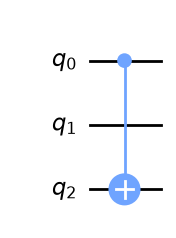

↑ f(x) = x₀: one CNOT from input 0 to the ancilla — f is 1 on exactly half of the inputs (those with x₀ = 1)

Oracle: balanced_2


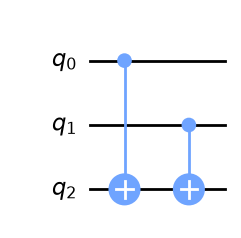

↑ f(x) = x₀ ⊕ x₁: two CNOTs into the ancilla — 1 when x₀ and x₁ differ, again half of the inputs

Oracle: constant_0


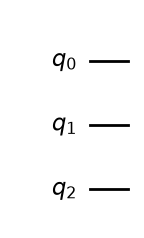

↑ f(x) = 0: no gate at all, the ancilla is never flipped

Oracle: constant_1


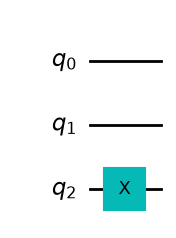

↑ f(x) = 1: one X on the ancilla, applied whatever the input is


In [3]:
# Test: Create and visualize each oracle type
n = 2  # Number of input qubits
oracle_types = ['balanced_1', 'balanced_2', 'constant_0', 'constant_1']   # a Python list of strings

print(f"Oracle Examples (for n={n} input qubits):\n")
for otype in oracle_types:
    oracle = create_oracle(n, otype)
    print(f"{otype:15s} - Gates: {oracle.size():2d}, Depth: {oracle.depth()}")   # :15s / :2d = pad to a fixed width -> aligned columns

# Visualize every oracle (the original showed only constant_1)
captions = {                                                   # a dict {key: value}: one caption per oracle
    'balanced_1': "f(x) = x₀: one CNOT from input 0 to the ancilla — f is 1 on exactly half of the inputs (those with x₀ = 1)",
    'balanced_2': "f(x) = x₀ ⊕ x₁: two CNOTs into the ancilla — 1 when x₀ and x₁ differ, again half of the inputs",
    'constant_0': "f(x) = 0: no gate at all, the ancilla is never flipped",
    'constant_1': "f(x) = 1: one X on the ancilla, applied whatever the input is",
}
for otype in oracle_types:
    print("\n" + "="*50)
    print(f"Oracle: {otype}")
    print("="*50)
    display(draw(create_oracle(n, otype))); print(f"↑ {captions[otype]}")


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `oracle.size()`, `oracle.depth()` | number of gates and of layers: 1, 2, 0, 1 gates — an oracle can be trivial and still be a valid black box |
| `f"{otype:15s}"` | an f-string with a format specifier: the name padded to 15 characters |
| `captions[otype]` | dictionary lookup: the caption that belongs to this oracle |
| `display(draw(...))` | one picture per oracle: inputs `q_0`, `q_1`, ancilla `q_2` (the bottom wire) |

</details>


### Step 3: Complete Deutsch-Jozsa Circuit

Now we build the complete algorithm with all four steps:
1. Initialize qubits
2. Apply Hadamard gates (create superposition)
3. Apply oracle
4. Apply Hadamard gates again (create interference)
5. Measure input qubits

In [4]:
def deutsch_jozsa_circuit(n_qubits: int, oracle_type: str) -> QuantumCircuit:
    """
    Build complete Deutsch-Jozsa circuit.

    Args:
        n_qubits: Number of input qubits
        oracle_type: Type of oracle ('balanced_1', 'balanced_2', 'constant_0', 'constant_1')

    Returns:
        QuantumCircuit: Complete Deutsch-Jozsa circuit with measurements
    """
    # Create quantum and classical registers
    # n input qubits + 1 ancilla qubit
    qr = QuantumRegister(n_qubits, 'input')            # QuantumRegister(size, name)
    ancilla = QuantumRegister(1, 'ancilla')
    cr = ClassicalRegister(n_qubits, 'output')          # its name 'output' becomes .data.output in the Sampler result

    circuit = QuantumCircuit(qr, ancilla, cr)          # qubits in order: input[0..n-1], then ancilla[0]

    # STEP 1: Initialize ancilla to |1⟩
    # Input qubits start in |0⟩ by default
    circuit.x(ancilla)                                  # a gate applied to a register acts on each of its qubits
    circuit.barrier(label='Init')                       # a barrier: a visual separator that also stops the transpiler from merging gates across it

    # STEP 2: Apply Hadamard to all qubits (create superposition)
    # Input qubits: |0⟩ → |+⟩ (equal superposition)
    # Ancilla: |1⟩ → |−⟩ (enables phase kickback)
    circuit.h(qr)
    circuit.h(ancilla)
    circuit.barrier(label='Superposition')

    # STEP 3: Apply Oracle
    # Query the function f(x) in superposition
    oracle = create_oracle(n_qubits, oracle_type)
    circuit.compose(oracle, inplace=True)               # glue the oracle onto qubits 0..n (inplace=True modifies circuit itself)
    circuit.barrier(label='Oracle')

    # STEP 4: Apply Hadamard to input qubits (create interference)
    # This causes constructive/destructive interference
    # Constant: constructive at |00...0⟩
    # Balanced: destructive at |00...0⟩
    circuit.h(qr)
    circuit.barrier(label='Interference')

    # STEP 5: Measure input qubits only
    # We don't measure the ancilla
    circuit.measure(qr, cr)                             # input[i] -> output[i]

    return circuit


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `QuantumCircuit(qr, ancilla, cr)` | a circuit made of named registers: n + 1 qubits and n classical bits |
| `circuit.x(ancilla)` then `circuit.h(ancilla)` | the ancilla goes to \|1⟩ and then to \|−⟩ = (\|0⟩ − \|1⟩)/√2: the state that turns the oracle's bit flip into a phase (box below) |
| `circuit.compose(oracle, inplace=True)` | inserts the oracle's gates on the first n + 1 qubits of the circuit |
| `barrier(label=...)` | a labelled separator: it marks the four stages in the drawing and keeps the transpiler from optimising across them |
| `circuit.measure(qr, cr)` | only the inputs are read: the ancilla stays in \|−⟩ and carries no information |

</details>


<details open><summary><b>📐 Working it out</b></summary>

**Phase kickback: why the ancilla is prepared in $|-\rangle$.** The oracle acts as $U_f|x\rangle|y\rangle = |x\rangle|y\oplus f(x)\rangle$. With $|y\rangle = |-\rangle = (|0\rangle - |1\rangle)/\sqrt2$:

$$U_f|x\rangle|-\rangle = |x\rangle\,\frac{|f(x)\rangle - |1\oplus f(x)\rangle}{\sqrt2}
=\begin{cases} |x\rangle|-\rangle & f(x)=0\\[2pt] -\,|x\rangle|-\rangle & f(x)=1\end{cases}
=(-1)^{f(x)}\,|x\rangle|-\rangle .$$

The ancilla is unchanged; the value of $f$ has moved into a **sign** in front of $|x\rangle$ — "kicked back" onto the input register. By linearity, on the uniform superposition

$$U_f\Big(\tfrac{1}{\sqrt{2^n}}\sum_x |x\rangle\Big)|-\rangle = \tfrac{1}{\sqrt{2^n}}\sum_x (-1)^{f(x)}|x\rangle\;|-\rangle ,$$

which is $|\psi_2\rangle$ of the Mathematical Foundation. Check with `constant_1`: $f\equiv1$ gives the same factor $-1$ on *every* term, a global phase that no measurement can see — so its histogram is identical to `constant_0`. If the ancilla started in $|0\rangle$ instead, $U_f$ would only entangle it with $x$ and no sign would appear: the Hadamards at the end would then return $|0\ldots0\rangle$ for every oracle.

</details>


Building Deutsch-Jozsa Circuits...

balanced_1      - Total qubits: 21, Depth: 5, Gates: 63
balanced_2      - Total qubits: 21, Depth: 6, Gates: 64
constant_0      - Total qubits: 21, Depth: 4, Gates: 62
constant_1      - Total qubits: 21, Depth: 5, Gates: 63

Complete Deutsch-Jozsa Circuit (Balanced Oracle 1)


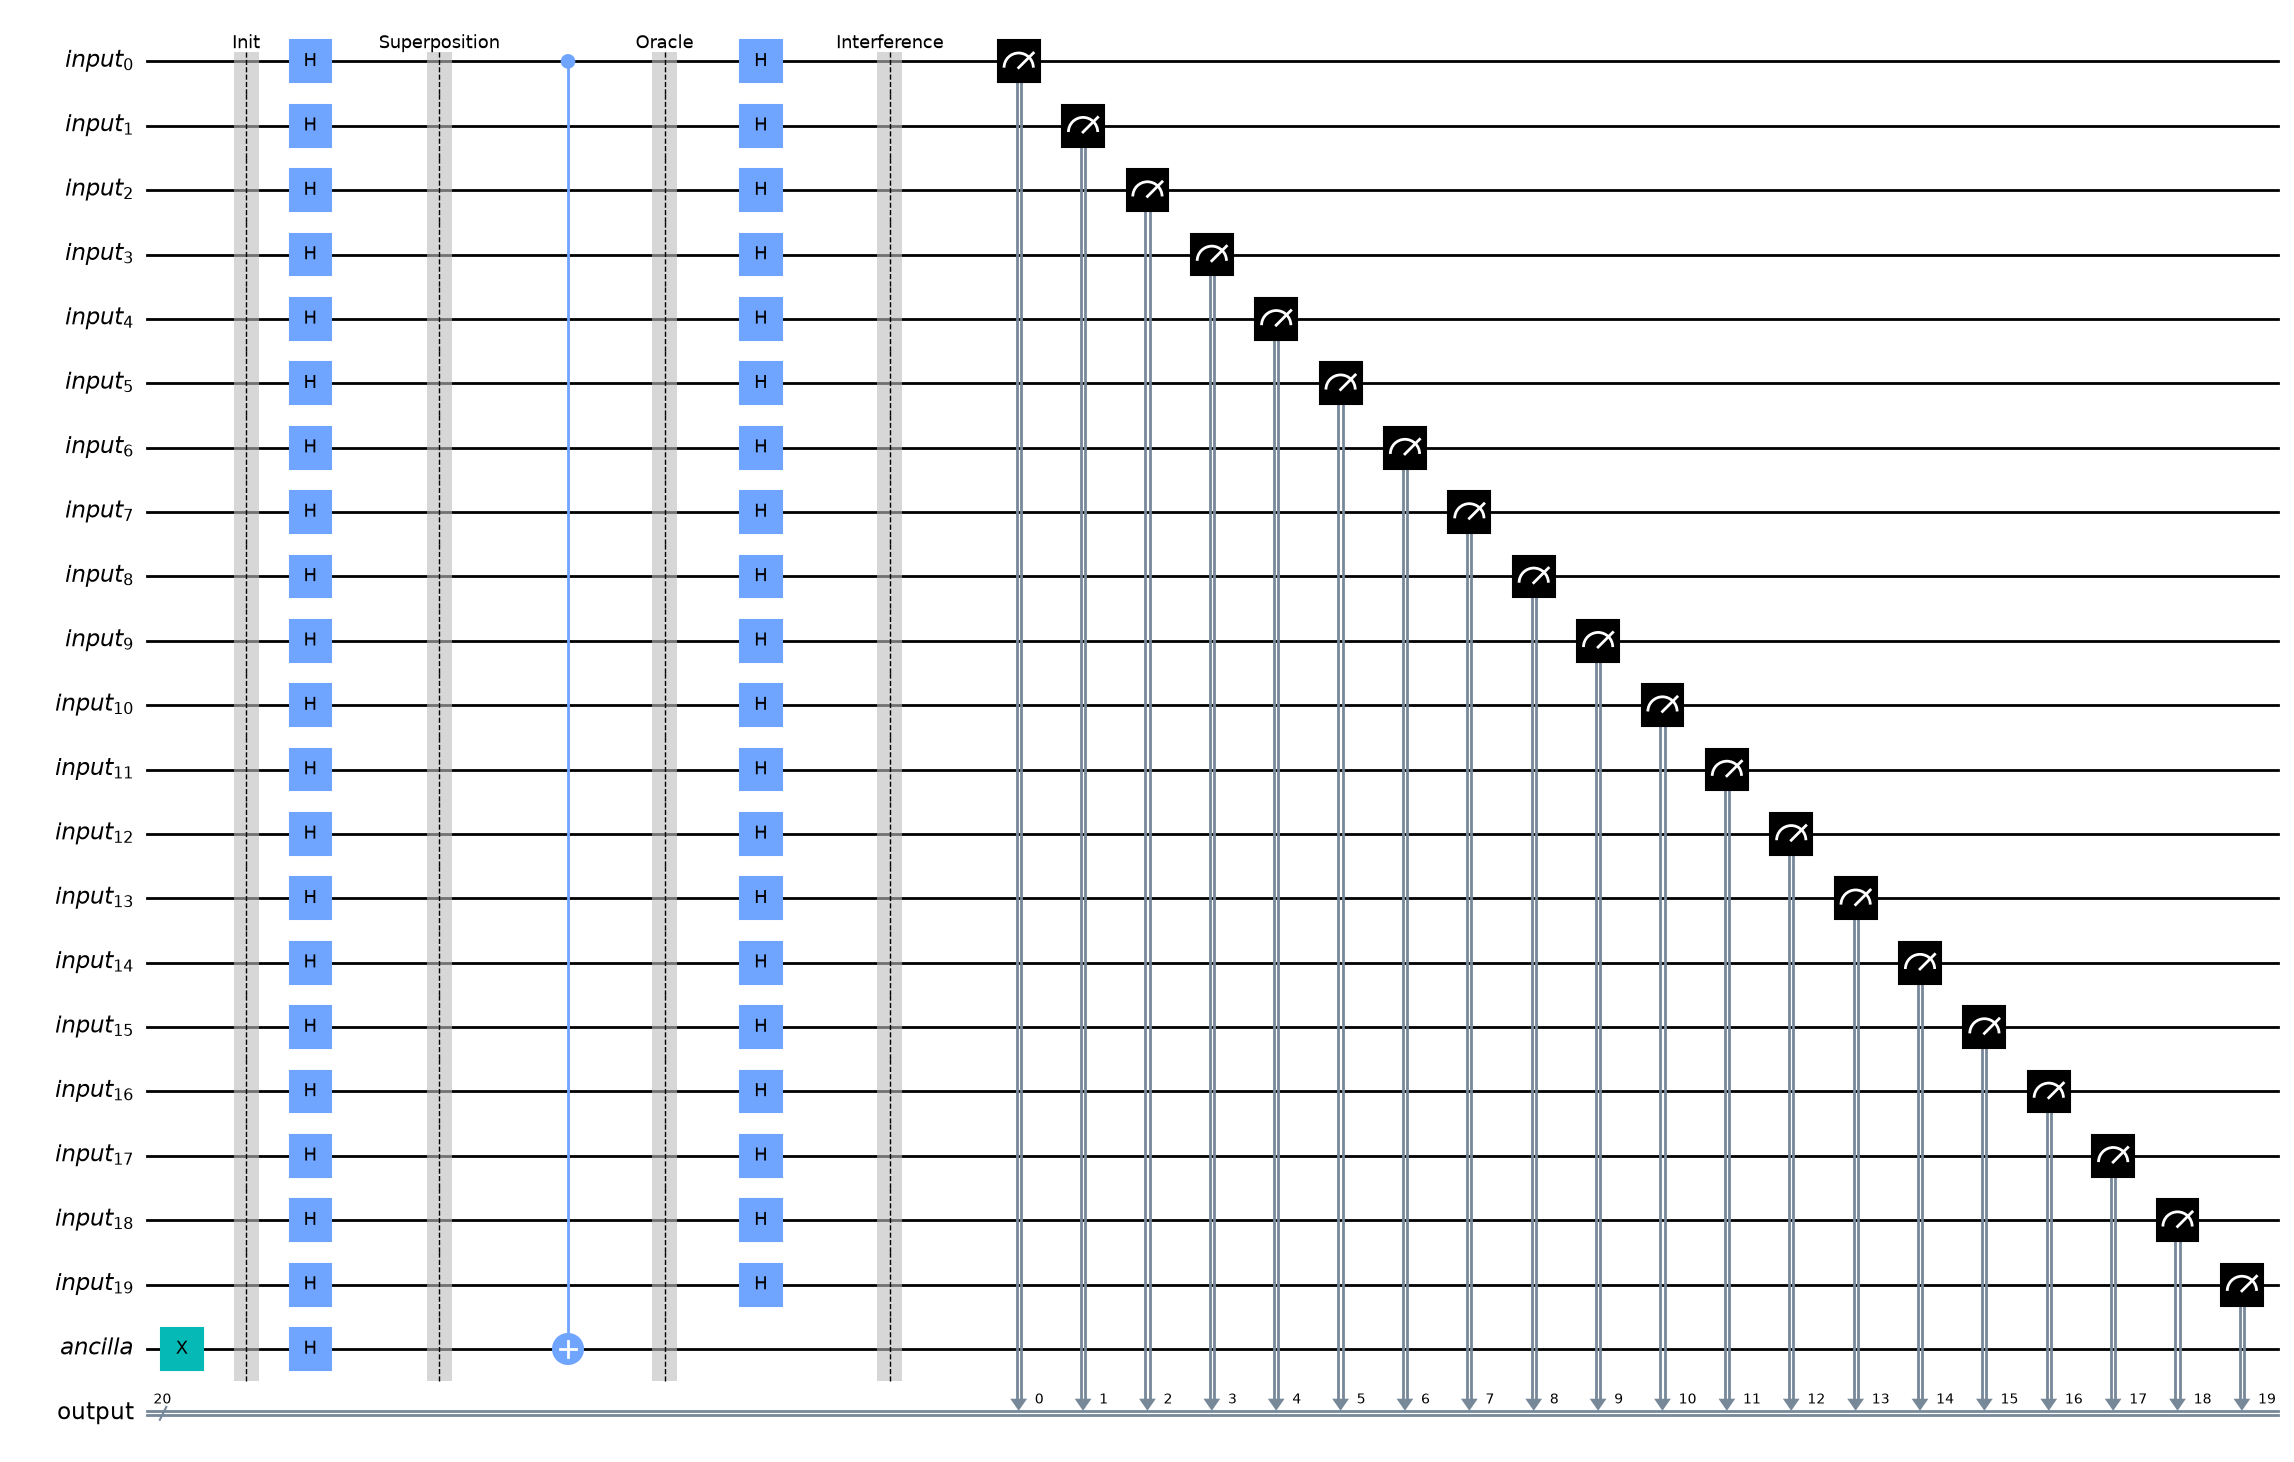

↑ the circuit we simulate: 20 input qubits + the ancilla; X and H prepare |+…+⟩|−⟩, the oracle is a single CNOT q0 → ancilla, H again, then 20 measurements


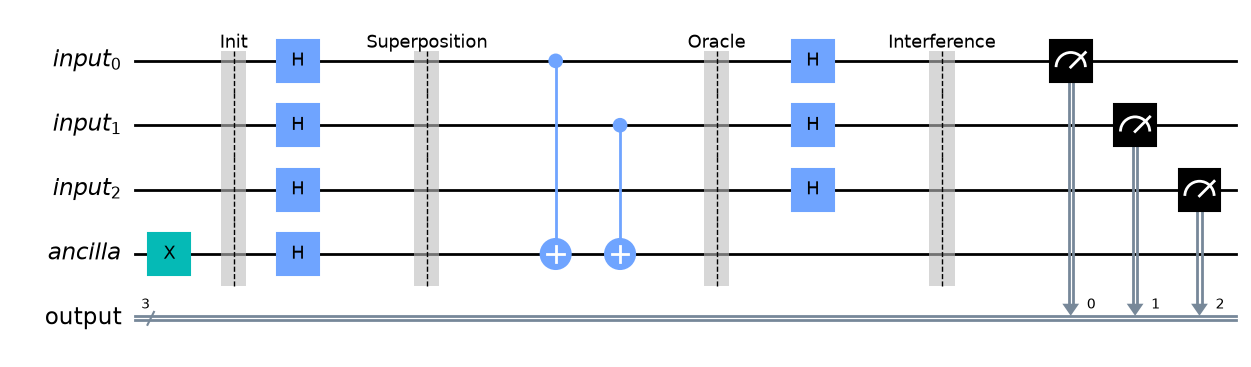

↑ the same structure with 3 inputs and the balanced_2 oracle (two CNOTs): the four stages Init / Superposition / Oracle / Interference are separated by labelled barriers


In [5]:
# Build circuits for all oracle types
print("Building Deutsch-Jozsa Circuits...\n")

n = 20 # number of input qubits: 20 inputs + 1 ancilla = 21 qubits (Aer simulates them easily; the drawings below use 3)
circuits = {}                                                   # dict {oracle name: circuit}

for otype in oracle_types:
    circuits[otype] = deutsch_jozsa_circuit(n, otype)
    print(f"{otype:15s} - Total qubits: {circuits[otype].num_qubits}, "
          f"Depth: {circuits[otype].depth()}, Gates: {circuits[otype].size()}")   # size() counts barriers and measurements too

# Visualize one complete circuit
print("\n" + "="*70)
print("Complete Deutsch-Jozsa Circuit (Balanced Oracle 1)")
print("="*70)
display(draw(circuits['balanced_1'])); print(f"↑ the circuit we simulate: {n} input qubits + the ancilla; X and H prepare |+…+⟩|−⟩, the oracle is a single CNOT q0 → ancilla, H again, then {n} measurements")
display(draw(deutsch_jozsa_circuit(3, 'balanced_2'))); print("↑ the same structure with 3 inputs and the balanced_2 oracle (two CNOTs): the four stages Init / Superposition / Oracle / Interference are separated by labelled barriers")


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `n = 20` | the author's choice: 21 qubits, far beyond what one could check by hand; the original comment said 3 — the small drawing uses 3 |
| `circuits[otype] = ...` | fills the dictionary: one complete circuit per oracle, reused by the simulation and hardware steps |
| Depth / Gates printed | only the oracle differs: 0 to 2 extra gates; everything else (X, 2 × H layers, barriers, measurements) is the same for every f |
| `display(draw(...))` × 2 | the full 21-qubit circuit and a readable 4-qubit one |

</details>


### Step 4: Local Simulation

Before running on hardware, let's test with Aer simulator to verify our implementation.

In [6]:
def run_simulation(circuit: QuantumCircuit, shots: int = 1024) -> Dict:
    """
    Run circuit on local Aer simulator using SamplerV2.

    Args:
        circuit: Quantum circuit to execute
        shots: Number of measurement shots

    Returns:
        Dict: Measurement counts
    """
    # Create Aer simulator
    simulator = AerSimulator()                     # ideal: no noise

    # Use SamplerV2 primitive (Qiskit 2.2 style)
    sampler = AerSampler()

    # Transpile circuit for simulator
    pm = generate_preset_pass_manager(optimization_level=1, backend=simulator)   # light optimisation for Aer's gate set
    transpiled = pm.run(circuit)

    # Run simulation
    job = sampler.run([transpiled], shots=shots)   # a list of circuits ('pubs'); returns a job
    result = job.result()                          # wait for it and collect the result

    # Extract counts from PubResult
    pub_result = result[0]                         # one entry per circuit submitted
    counts = pub_result.data.output.get_counts()   # .data.<classical register name>: 'output'

    return counts


# Run simulations for all oracle types
print("Running Simulations...\n")
print("="*70)

sim_results = {}
for otype in oracle_types:
    print(f"\nOracle: {otype}")
    print("-" * 40)

    counts = run_simulation(circuits[otype], shots=1024)
    sim_results[otype] = counts                    # kept for the comparison with hardware in Step 5

    # Interpret result
    all_zeros = '0' * n                            # string repetition: '000...0' with n characters
    if all_zeros in counts and counts[all_zeros] > 900:   # decision rule: (almost) all shots on 0...0 -> constant
        interpretation = "CONSTANT function"
    else:
        interpretation = "BALANCED function"

    print(f"  Result: {interpretation}")
    print(f"  Measurements: {counts}")

    # Expected result
    expected = "CONSTANT" if 'constant' in otype else "BALANCED"   # conditional expression (ternary); 'in' tests for a substring
    status = "✓" if expected in interpretation else "✗"
    print(f"  Expected: {expected} {status}")

print("\n" + "="*70)


Running Simulations...


Oracle: balanced_1
----------------------------------------


  Result: BALANCED function
  Measurements: {'00000000000000000001': 1024}
  Expected: BALANCED ✓

Oracle: balanced_2
----------------------------------------
  Result: BALANCED function
  Measurements: {'00000000000000000011': 1024}
  Expected: BALANCED ✓

Oracle: constant_0
----------------------------------------
  Result: CONSTANT function
  Measurements: {'00000000000000000000': 1024}
  Expected: CONSTANT ✓

Oracle: constant_1
----------------------------------------


  Result: CONSTANT function
  Measurements: {'00000000000000000000': 1024}
  Expected: CONSTANT ✓



<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `generate_preset_pass_manager(...).run(circuit)` | rewrites the circuit in gates the simulator supports (barriers and registers are kept) |
| `sampler.run([transpiled], shots=shots)` | 1024 repetitions of the circuit; SamplerV2 always takes a *list* of circuits |
| `result[0].data.output.get_counts()` | circuit 0, classical register `output` → a dict {bitstring: shots}; the rightmost character is qubit 0 |
| `counts[all_zeros] > 900` | the author's decision rule: constant if more than ~88 % of the shots give 0…0 — on an ideal simulator it is 1024 or 0 |
| one key per oracle | constant → `000…0` every shot; `balanced_1` → `0…01`, `balanced_2` → `0…011`: deterministic outcomes, see the box |

</details>


<details open><summary><b>📐 Working it out</b></summary>

**The amplitude of $|0\ldots0\rangle$ — and of every other string.** After the last Hadamards ($H^{\otimes n}|x\rangle = 2^{-n/2}\sum_z (-1)^{x\cdot z}|z\rangle$) the input register is in

$$|\psi_3\rangle = \sum_z a_z|z\rangle,\qquad a_z = \frac{1}{2^n}\sum_{x}(-1)^{f(x)+x\cdot z}.$$

For $z = 0\ldots0$ the factor $(-1)^{x\cdot z}$ is 1 and

$$a_{0\ldots0} = \frac{1}{2^n}\sum_x(-1)^{f(x)} = \begin{cases}\pm 1 & f \text{ constant (every term equal)}\\ 0 & f \text{ balanced } (2^{n-1} \text{ terms } +1,\ 2^{n-1} \text{ terms } -1)\end{cases}$$

so $P(0\ldots0) = |a_{0\ldots0}|^2$ is exactly 1 or exactly 0: one query decides. For the two balanced oracles we can do better and find *which* string comes out. $f(x) = x_0$: $(-1)^{x_0 + x\cdot z} = (-1)^{x\cdot(z\oplus e_0)}$ and $\sum_x (-1)^{x\cdot w} = 2^n\,\delta_{w,0}$, so $a_z = 1$ for $z = e_0$ (only qubit 0 set) and 0 otherwise. Qiskit prints qubit 0 as the **rightmost** character: `00000000000000000001` with 1024/1024 shots. Likewise $f = x_0\oplus x_1$ gives $z = e_0 + e_1$ = `00000000000000000011`, and both constants give `00000000000000000000` — the four `Measurements:` lines above.

</details>


### Visualization of Simulation Results

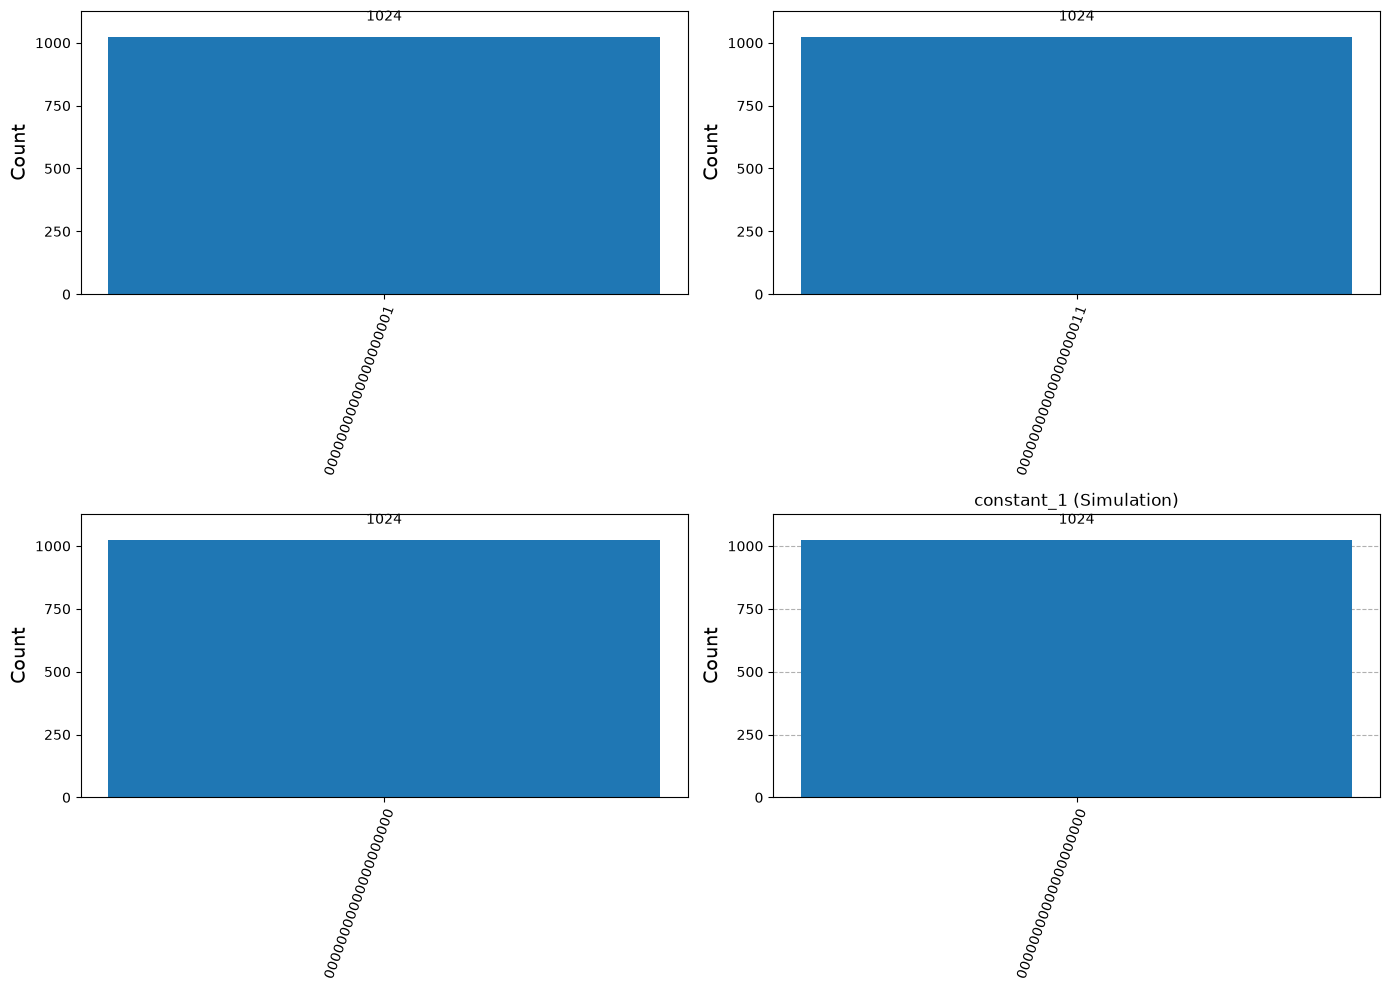

↑ one bar per panel: the ideal simulator always returns the same string — 0…01 (balanced_1), 0…011 (balanced_2), 0…0 (both constants)

📊 Observations:
  • Constant functions: Measure |000⟩ with ~100% probability
  • Balanced functions: Measure any state EXCEPT |000⟩
  • Perfect results expected in simulation (no noise)


In [7]:
# Create comparison plot
fig, axes = plt.subplots(2, 2, figsize=(14, 10))   # a 2 x 2 grid of axes in one figure
axes = axes.flatten()                               # 2-D array of axes -> a flat list of 4

for idx, otype in enumerate(oracle_types):          # enumerate gives (position, element)
    plot_histogram(sim_results[otype], ax=axes[idx],
                   title=f"{otype} (Simulation)")   # ax= : draw into this panel

plt.tight_layout()
plt.show()
print("↑ one bar per panel: the ideal simulator always returns the same string — 0…01 (balanced_1), 0…011 (balanced_2), 0…0 (both constants)")

print("\n📊 Observations:")
print("  • Constant functions: Measure |000⟩ with ~100% probability")
print("  • Balanced functions: Measure any state EXCEPT |000⟩")
print("  • Perfect results expected in simulation (no noise)")


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `plt.subplots(2, 2)` + `axes.flatten()` | four panels addressed as `axes[0]` … `axes[3]` |
| `plot_histogram(counts, ax=...)` | Qiskit's bar chart of a counts dict, drawn into the chosen panel |
| a single bar of 1024 | the signature of an ideal deterministic algorithm: no statistics needed, one shot would be enough |

</details>


### Step 5: IBM Quantum Hardware Execution

Now let's run on real quantum hardware! This demonstrates quantum computing in practice.

#### 5.1 IBM Quantum Account Setup

First-time users need to save their IBM Quantum credentials.

In [8]:
# FIRST TIME ONLY: Save your IBM Quantum account
# Paste your token in IBM_TOKEN and run this cell once (then empty IBM_TOKEN again: never commit a token!)

from qiskit_ibm_runtime import QiskitRuntimeService

IBM_TOKEN = ""   # Use the 44-character API_KEY you created and saved from the IBM Quantum Platform Home dashboard

if IBM_TOKEN:                                   # an empty string is False: without a token nothing is saved
    try:
        QiskitRuntimeService.save_account(
          token=IBM_TOKEN,
          name="Roberto Cappuccio", # Optional
          instance="open-instance", # Optional
          set_as_default=True, # Optional
          overwrite=True, # Optional
        )
        print("✓ Account saved successfully!")
    except Exception as e:                      # e.g. InvalidAccountError for a malformed token
        print(f"⚠ Could not save the account: {e}")
else:
    print("ℹ IBM_TOKEN is empty: no account saved (fine if you saved one before, or if you only simulate).")

# Get your token from: https://quantum.ibm.com/account


ℹ IBM_TOKEN is empty: no account saved (fine if you saved one before, or if you only simulate).


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `IBM_TOKEN = ""` + `if IBM_TOKEN:` | the original cell called `save_account(token="")` unconditionally and stopped the notebook with `InvalidAccountError`; now an empty token just prints a message |
| `QiskitRuntimeService.save_account(...)` | writes the token to `~/.qiskit/qiskit-ibm.json` once; later sessions load it with `QiskitRuntimeService()` |
| `try: ... except Exception as e:` | a wrong token becomes a printed message instead of an error |

</details>


In [9]:
try:
    service = QiskitRuntimeService()            # load the default account saved on this computer
except Exception as e:                          # AccountNotFoundError without a saved account
    service = None
    print(f"⚠ No IBM Quantum account ({type(e).__name__}): the hardware cells below will be skipped.")


⚠ No IBM Quantum account (AccountNotFoundError): the hardware cells below will be skipped.


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `QiskitRuntimeService()` | with no arguments it reads the saved default account; without one it raises `AccountNotFoundError` (the bare original line stopped the notebook here) |
| `service = None` | the flag the next cells test: no account → skip with a message |

</details>


In [10]:
# Load IBM Quantum service (run every session)
try:
    service = QiskitRuntimeService()
    print("✓ IBM Quantum service loaded successfully!")
    print(f"  Channel: {service.channel}")
except Exception as e:
    print(f"⚠ Error loading service: {e}")
    print("  Please save your account first using the cell above.")
    service = None                              # flag for the backend-selection cells


⚠ Error loading service: "Unable to find account. Please make sure an account with the channel name 'ibm_quantum_platform' is saved."
  Please save your account first using the cell above.


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `try` / `except` | the author's guarded version of the previous cell, with a hint on what to do |
| `service.channel` | which IBM API the account uses (`ibm_quantum_platform`) |
| `service = None` (added) | without it `service` would stay undefined and the next cell would raise `NameError` |

</details>


#### 5.2 Backend Selection

Choose an appropriate quantum backend based on:
- Number of qubits needed
- Queue length
- Quantum volume
- Error rates

In [11]:
# List available quantum backends
print("Available IBM Quantum Backends:\n")
print("="*80)

if service is not None:                         # added guard: listing needs an account
    backends = service.backends(
        simulator=False,
        operational=True,
        min_num_qubits=156  # the n = 20 circuit needs 21 qubits; 156 keeps only the large Heron devices
    )

    backend_info = []
    for backend in backends:
        status = backend.status()               # live data: operational flag, queue length
        config = backend.configuration()        # static data: number of qubits, basis gates

        info = {
            'name': backend.name,
            'qubits': config.n_qubits,
            'pending_jobs': status.pending_jobs,
            'operational': status.operational,
            'status_msg': status.status_msg
        }
        backend_info.append(info)

        print(f"Backend: {info['name']}")
        print(f"  Qubits: {info['qubits']}")
        print(f"  Queue: {info['pending_jobs']} jobs")
        print(f"  Status: {info['status_msg']}")
        print("-" * 80)

    if not backends:                            # an empty list is False
        print("⚠ No backends available. You may need to:")
        print("  1. Join the IBM Quantum Network")
        print("  2. Wait for backends to become operational")
        print("  3. Check your account access level")
else:
    print("⚠ No IBM Quantum service loaded: backend listing skipped.")


Available IBM Quantum Backends:

⚠ No IBM Quantum service loaded: backend listing skipped.


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `service.backends(simulator=False, operational=True, min_num_qubits=156)` | the real devices visible to your account that are up and have at least 156 qubits |
| `backend.status()` vs `backend.configuration()` | live data (`pending_jobs` = queue length) vs static data (`n_qubits`) |
| `if service is not None:` | added guard: offline the cell prints one line instead of raising `AttributeError` |

</details>


In [12]:
# Select the least busy backend
try:
    if service is None:                         # added: a clear message instead of "'NoneType' object has no attribute ..."
        raise RuntimeError("no IBM Quantum account loaded")
    backend = service.least_busy(
        operational=True,
        simulator=False,
        min_num_qubits=4
    )

    print(f"✓ Selected backend: {backend.name}")
    print(f"  Qubits: {backend.configuration().n_qubits}")
    print(f"  Pending jobs: {backend.status().pending_jobs}")

    # Get backend properties
    props = backend.properties()                # calibration data: T1, T2, gate and readout errors per qubit
    if props:
        # Average T1 and T2 times
        t1_avg = np.mean([props.t1(i) for i in range(backend.configuration().n_qubits)])   # list comprehension over all qubits
        t2_avg = np.mean([props.t2(i) for i in range(backend.configuration().n_qubits)])
        print(f"  Avg T1: {t1_avg*1e6:.1f} μs")  # seconds -> microseconds
        print(f"  Avg T2: {t2_avg*1e6:.1f} μs")

except Exception as e:
    print(f"⚠ Could not select backend: {e}")
    print("  Continuing with simulation only.")
    backend = None                              # the flag of every following hardware cell


⚠ Could not select backend: no IBM Quantum account loaded
  Continuing with simulation only.


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `service.least_busy(...)` | the device with the shortest queue among those passing the filters |
| `props.t1(i)`, `props.t2(i)` | relaxation and dephasing times of qubit i: tens to hundreds of µs on current IBM chips — the time budget of a circuit |
| `raise RuntimeError(...)` inside `try` | offline the `except` branch prints `Could not select backend: no IBM Quantum account loaded` and sets `backend = None` |

</details>


#### 5.3 Circuit Transpilation

Transpile our circuit to match the hardware's native gate set and topology.

⚠ Skipping transpilation (no backend selected)

Offline preview — FakeManilaV2, n = 3, balanced_2: depth 10, gates {'rz': 14, 'sx': 7, 'barrier': 4, 'measure': 3, 'cx': 2, 'x': 1}


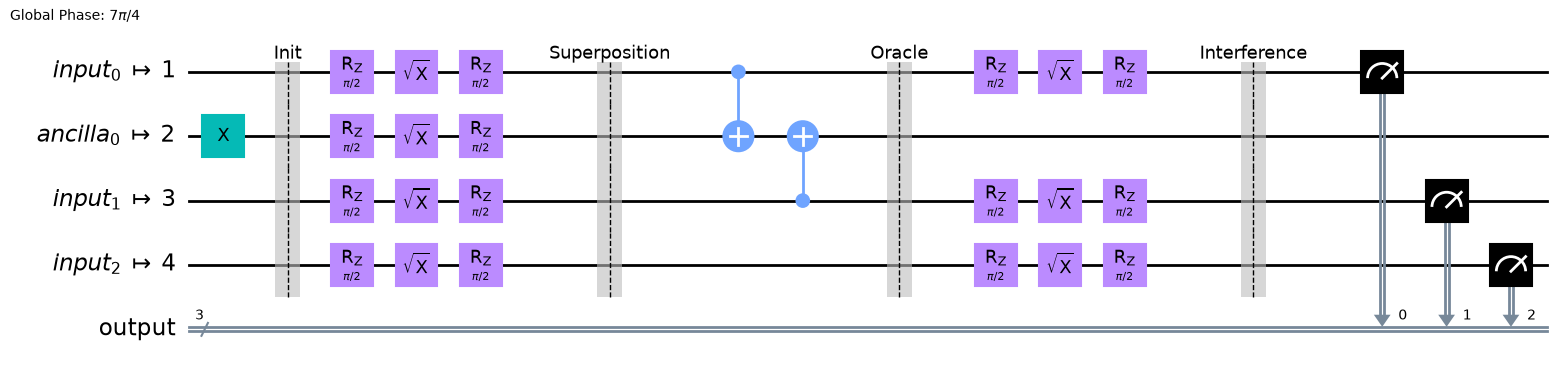

↑ the ISA circuit for a 5-qubit IBM chip: every H became rz/sx rotations, the two CNOTs stay native cx gates on connected physical qubits (left labels = physical qubit numbers)


In [13]:
if backend is not None:
    # Choose which oracle to test on hardware
    test_oracle = 'balanced_1'  # Change to test different oracles
    test_circuit = circuits[test_oracle]

    print(f"Transpiling circuit for {backend.name}...\n")

    # Generate optimized pass manager for target backend
    pm = generate_preset_pass_manager(
        optimization_level=3,  # Maximum optimization
        backend=backend        # native gates + coupling map + calibration of this device
    )

    # Transpile
    transpiled = pm.run(test_circuit)           # the ISA circuit: native gates on physical qubits

    # Compare original vs transpiled
    print("Circuit Comparison:")
    print("=" * 60)
    print(f"{'Metric':<25} {'Original':>15} {'Transpiled':>15}")   # :<25 left-aligned, :>15 right-aligned
    print("-" * 60)
    print(f"{'Qubits':<25} {test_circuit.num_qubits:>15} {transpiled.num_qubits:>15}")
    print(f"{'Depth':<25} {test_circuit.depth():>15} {transpiled.depth():>15}")
    print(f"{'Gate count':<25} {test_circuit.size():>15} {transpiled.size():>15}")
    print(f"{'2-qubit gates':<25} {test_circuit.num_nonlocal_gates():>15} {transpiled.num_nonlocal_gates():>15}")
    print("=" * 60)

    # Show transpiled gate distribution
    print("\nTranspiled gate distribution:")
    for gate, count in sorted(transpiled.count_ops().items()):
        print(f"  {gate}: {count}")

    # Visualize transpiled circuit (if not too large)
    if transpiled.depth() < 100:
        print("\nTranspiled Circuit:")
        display(draw(transpiled, idle_wires=False)); print(f"↑ the ISA circuit for {backend.name}: H became rz/sx rotations, the CNOT a native two-qubit gate; idle_wires=False hides the unused physical qubits")
else:
    print("⚠ Skipping transpilation (no backend selected)")
    # Offline preview: the same algorithm with 3 inputs, transpiled for the 5-qubit fake device FakeManilaV2
    # (a calibration snapshot shipped with qiskit-ibm-runtime: gates + coupling map, no account needed)
    from qiskit_ibm_runtime.fake_provider import FakeManilaV2
    preview = generate_preset_pass_manager(optimization_level=3, backend=FakeManilaV2()).run(deutsch_jozsa_circuit(3, 'balanced_2'))
    print(f"\nOffline preview — FakeManilaV2, n = 3, balanced_2: depth {preview.depth()}, gates {dict(preview.count_ops())}")
    display(draw(preview, idle_wires=False)); print("↑ the ISA circuit for a 5-qubit IBM chip: every H became rz/sx rotations, the two CNOTs stay native cx gates on connected physical qubits (left labels = physical qubit numbers)")


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `generate_preset_pass_manager(optimization_level=3, backend=backend)` | the transpiler built for this device: layout on physical qubits, routing on the coupling map, translation to native gates, optimisation |
| `num_nonlocal_gates()` | the two-qubit gates — the noisiest operations, the number to watch |
| `draw(transpiled, idle_wires=False)` | only the qubits actually used: a 156-qubit chip would otherwise give 156 wires |
| `else:` offline preview | added: without an account the same step is shown on `FakeManilaV2`, a 5-qubit snapshot of a retired IBM device |

</details>


#### 5.4 Job Submission and Monitoring

Submit our circuit to the quantum computer and monitor its execution.

In [14]:
job = None                                      # added: stays None when nothing is submitted
if backend is not None:
    print(f"Submitting job to {backend.name}...\n")

    # Create Sampler with backend
    sampler = IBMSampler(backend)               # SamplerV2 bound to one device (job mode)

    # Submit job
    shots = 1024
    job = sampler.run([transpiled], shots=shots)   # asynchronous: returns at once, the job waits in the device queue

    print(f"✓ Job submitted successfully!")
    print(f"  Job ID: {job.job_id()}")          # keep it: service.job(id) retrieves the result later
    print(f"  Initial status: {job.status()}")
    print(f"  Shots requested: {shots}")
    print("\n" + "="*70)
    print("Monitoring job progress...")
    print("(This may take several minutes depending on queue)")
    print("="*70 + "\n")

    # Monitor job with timeout
    max_wait = 3600  # 1 hour maximum
    check_interval = 30  # Check every 30 seconds
    elapsed = 0
else:
    print("⚠ No backend: nothing submitted")

# The 🔬 In-depth analysis runs circuits through run_circuit(circuit, shots). In this edition it is an offline
# noisy stand-in for a device: Aer with the noise model of the 5-qubit FakeManilaV2 snapshot (no account, no quota).
from qiskit_ibm_runtime.fake_provider import FakeManilaV2
from qiskit_aer.noise import NoiseModel
noisy_sim = AerSimulator(noise_model=NoiseModel.from_backend(FakeManilaV2()))   # gate errors, readout errors, T1/T2 of the snapshot
pm_noisy = generate_preset_pass_manager(optimization_level=1, backend=FakeManilaV2())   # map the circuit onto Manila's gates and qubits

def run_circuit(circuit, shots=1024):
    """Transpile for FakeManilaV2 + noisy Aer run + counts in one call (used by the In-depth analysis)."""
    return noisy_sim.run(pm_noisy.run(circuit), shots=shots).result().get_counts()


⚠ No backend: nothing submitted


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `IBMSampler(backend)` + `sampler.run([transpiled], shots=shots)` | the hardware SamplerV2: it accepts only ISA (transpiled) circuits and returns a job immediately |
| `job = None` before the `if` | added: the next cells test `if job is not None` instead of failing with `NameError` |
| `NoiseModel.from_backend(FakeManilaV2())` | the error rates of a real 5-qubit IBM device turned into an Aer noise model: the offline stand-in used by `run_circuit` |
| `run_circuit(circuit, shots)` | transpile for Manila + noisy run + counts: the In-depth analysis calls only this, so its cells are the same in the IQM edition |

</details>


In [15]:
if job is not None:                             # added guard: the original line raised NameError without a job
    print(job.status())                         # 'QUEUED', 'RUNNING', 'DONE', ... (a plain string in qiskit-ibm-runtime >= 0.40)
else:
    print("No job submitted (no backend): nothing to query")


No job submitted (no backend): nothing to query


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `job.status()` | asks the server for the job state; a string such as `'QUEUED'` in recent runtime versions |
| `if job is not None` | added: offline this prints a message |

</details>


In [16]:
if backend is not None and job is not None:
    start_time = time.time()

    def status_name(s):
        return getattr(s, "name", s)            # runtime >= 0.40 returns a plain string, older versions an enum with .name

    while job.status() not in ['DONE', 'ERROR', 'CANCELLED']:
        time.sleep(check_interval)              # polling: wait, then ask again
        elapsed = int(time.time() - start_time)

        status = job.status()
        queue_pos = getattr(job, "queue_position", lambda: None)()   # not available on RuntimeJobV2: None instead of AttributeError

        # Format time
        mins, secs = divmod(elapsed, 60)        # divmod(a, b) = (a // b, a % b)
        time_str = f"{mins:02d}:{secs:02d}"     # :02d = two digits with a leading zero
        print(status, queue_pos)

        print(f"[{time_str}] Status: {status_name(status):<12}", end="")   # end="" = no newline: the next print continues the line
        if queue_pos is not None:
            print(f" | Queue position: {queue_pos}")
        else:
            print(" | Running...")

        if elapsed >= max_wait:
            print(f"\n⚠ Maximum wait time ({max_wait}s) exceeded!")
            print("  Job may still complete - check later using job ID")
            break

    # Check final status
    final_status = job.status()
    print("\n" + "="*70)

    if status_name(final_status) == 'DONE':
        print("✓ Job completed successfully!")
        result = job.result()
        hardware_counts = result[0].data.output.get_counts()   # same register name as in the simulation
        print(f"  Total execution time: {elapsed}s ({elapsed/60:.1f} min)")
    else:
        print(f"✗ Job ended with status: {status_name(final_status)}")
        hardware_counts = None

else:
    print("⚠ Skipping hardware execution (no backend selected)")
    hardware_counts = None


⚠ Skipping hardware execution (no backend selected)


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `while job.status() not in [...]` | polling loop: sleep `check_interval` s, ask the status, print, until a final state or the 1-hour limit |
| `getattr(s, "name", s)` | fix: in qiskit-ibm-runtime ≥ 0.40 `job.status()` is a string and the original `status.name` raised `AttributeError` |
| `getattr(job, "queue_position", lambda: None)()` | fix: `RuntimeJobV2` has no `queue_position()`; a default function returning `None` keeps the loop alive |
| `result[0].data.output.get_counts()` | the same extraction as in `run_simulation`: register `output` of circuit 0 |
| `hardware_counts = None` | offline value read by the results cell |

</details>


#### 5.5 Execution Time Analysis

In [17]:
if backend is not None:
    print("⏱️  Execution Time Breakdown\n")
    print("="*70)

    # Get timing constraints
    config = backend.configuration()

    # Estimate execution time per shot
    # Rough estimate based on typical gate times
    avg_gate_time = 100e-9  # ~100 ns per gate
    circuit_execution = transpiled.depth() * avg_gate_time   # layers run one after the other; gates in a layer run in parallel
    total_execution = circuit_execution * shots

    print(f"Circuit Execution (per shot):")
    print(f"  Gates: {transpiled.size()}")
    print(f"  Depth: {transpiled.depth()}")
    print(f"  Est. time: {circuit_execution*1e6:.1f} μs")
    print(f"\nTotal Quantum Execution:")
    print(f"  Shots: {shots}")
    print(f"  Est. time: {total_execution*1e3:.2f} ms")
    print(f"\nActual Total Time: {elapsed}s ({elapsed/60:.1f} min)")
    print(f"  Includes: Queue time + Circuit execution + Data transfer")

    # IBM Quantum free tier info
    print("\n" + "="*70)
    print("💡 IBM Quantum Free Tier Information:")
    print("  • 10 minutes of quantum computing time per month")
    print(f"  • This job used: ~{total_execution:.4f}s of quantum time")
    print(f"  • Remaining approx: ~{600-total_execution:.1f}s this month")
    print("  • Queue time does NOT count against your quota")
    print("="*70)
else:
    print("⚠ Skipping time analysis (no hardware execution)")


⚠ Skipping time analysis (no hardware execution)


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `transpiled.depth() * avg_gate_time` | per-shot time ≈ number of layers × 100 ns; real devices add ~1 µs readout and a qubit reset per shot |
| `* shots` | shots run one after the other, so quantum time grows linearly with them |
| `elapsed` | wall-clock time measured by the polling loop: dominated by the queue, not by the circuit |

</details>


## 📊 Results Analysis

Compare simulation results with hardware results to understand quantum noise effects.

In [18]:
if hardware_counts is not None:
    # Visualize comparison
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))   # two panels side by side, unpacked into ax1, ax2

    # Simulation results
    plot_histogram(sim_results[test_oracle], ax=ax1,
                   title=f"{test_oracle} - Simulation (Ideal)")

    # Hardware results
    plot_histogram(hardware_counts, ax=ax2,
                   title=f"{test_oracle} - Hardware ({backend.name})")

    plt.tight_layout()
    plt.show()
    print("↑ left: the ideal single bar; right: the hardware histogram — the same dominant string plus noise spread over neighbouring strings")

    # Analyze results
    print("\n" + "="*70)
    print("RESULTS ANALYSIS")
    print("="*70)

    # Check if we measure all zeros
    all_zeros = '0' * n

    sim_zeros_prob = sim_results[test_oracle].get(all_zeros, 0) / 1024   # .get(key, 0): 0 if the string never appeared
    hw_zeros_prob = hardware_counts.get(all_zeros, 0) / shots

    print(f"\nProbability of measuring |000...0⟩:")
    print(f"  Simulation: {sim_zeros_prob:.3f}")
    print(f"  Hardware:   {hw_zeros_prob:.3f}")

    # Interpretation
    expected_type = "CONSTANT" if 'constant' in test_oracle else "BALANCED"

    if expected_type == "CONSTANT":
        print(f"\nExpected: CONSTANT (should measure ~100% |000...0⟩)")
        if hw_zeros_prob > 0.8:
            print("✓ Hardware correctly identifies as CONSTANT")
        else:
            print("⚠ Hardware result affected by noise")
    else:
        print(f"\nExpected: BALANCED (should NOT measure |000...0⟩)")
        if hw_zeros_prob < 0.2:
            print("✓ Hardware correctly identifies as BALANCED")
        else:
            print("⚠ Hardware result affected by noise")

    # Calculate fidelity
    from qiskit.quantum_info import hellinger_fidelity

    fidelity = hellinger_fidelity(sim_results[test_oracle], hardware_counts)   # (sum_x sqrt(p_x q_x))^2: 1 = identical distributions
    print(f"\nHellinger Fidelity: {fidelity:.4f}")
    print("  (1.0 = perfect match, 0.0 = completely different)")

    if fidelity > 0.9:
        print("  ✓ Excellent agreement with simulation")
    elif fidelity > 0.7:
        print("  ✓ Good agreement (typical for NISQ devices)")
    else:
        print("  ⚠ Significant noise effects observed")

    print("\n" + "="*70)
    print("💡 Key Observations:")
    print("  • Hardware results show noise effects (decoherence, gate errors)")
    print("  • Correct answer still usually visible in measurements")
    print("  • Error mitigation techniques can improve results")
    print("  • Deeper circuits are more affected by noise (NISQ era)")
    print("="*70)

else:
    print("⚠ No hardware results to analyze")
    print("  Run the hardware execution cells above to compare results")


⚠ No hardware results to analyze
  Run the hardware execution cells above to compare results


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `hardware_counts.get(all_zeros, 0) / shots` | the estimated P(0…0): the quantity that decides constant vs balanced |
| `hw_zeros_prob > 0.8` / `< 0.2` | noise-tolerant thresholds instead of the exact 1 / 0 of the ideal case |
| `hellinger_fidelity(p, q)` | (Σₓ √(pₓ qₓ))²: overlap of the two normalised histograms, 1 for identical ones |
| `else:` branch | offline (no account) the cell only prints that there is nothing to compare; task 2 of the In-depth analysis does the comparison on a noisy stand-in |

</details>


## ⚡ Complexity Comparison

Let's visualize why the Deutsch-Jozsa algorithm demonstrates quantum advantage.

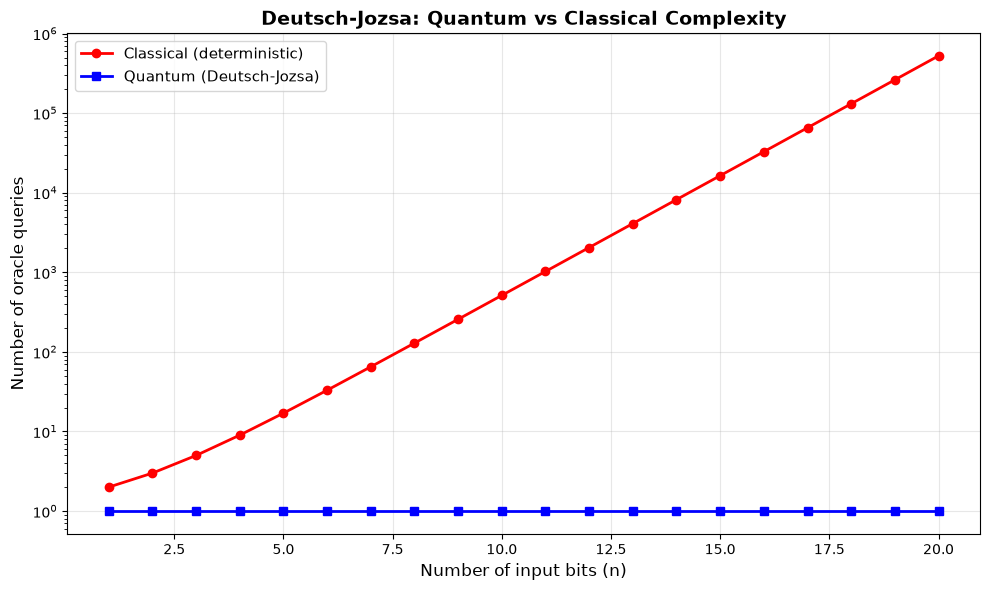

↑ on a log scale the classical worst case 2^(n−1) + 1 is a straight line rising by a factor 2 per bit; the quantum algorithm stays at 1 query

📈 Complexity Analysis:
n     Classical Queries    Quantum Queries      Speedup        
----------------------------------------------------------------------
3     5                    1                    5x
5     17                   1                    17x
10    513                  1                    513x
15    16,385               1                    16,385x
20    524,289              1                    524,289x

💡 Key Insight:
  The quantum speedup is EXPONENTIAL!
  For n=20 bits, quantum is ~500,000x faster!
  This demonstrates quantum supremacy for this specific problem.


In [19]:
# Compare classical vs quantum complexity
n_values = np.arange(1, 21)                      # NumPy array 1, 2, ..., 20
classical_queries = 2**(n_values-1) + 1  # Deterministic worst case (element-wise on the array)
quantum_queries = np.ones_like(n_values)  # Always 1 query

plt.figure(figsize=(10, 6))
plt.semilogy(n_values, classical_queries, 'r-o', label='Classical (deterministic)', linewidth=2)   # logarithmic y axis: an exponential becomes a straight line
plt.semilogy(n_values, quantum_queries, 'b-s', label='Quantum (Deutsch-Jozsa)', linewidth=2)
plt.xlabel('Number of input bits (n)', fontsize=12)
plt.ylabel('Number of oracle queries', fontsize=12)
plt.title('Deutsch-Jozsa: Quantum vs Classical Complexity', fontsize=14, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()
print("↑ on a log scale the classical worst case 2^(n−1) + 1 is a straight line rising by a factor 2 per bit; the quantum algorithm stays at 1 query")

print("\n📈 Complexity Analysis:")
print("="*70)
print(f"{'n':<5} {'Classical Queries':<20} {'Quantum Queries':<20} {'Speedup':<15}")   # :<20 = left-aligned in 20 characters
print("-"*70)
for n_val in [3, 5, 10, 15, 20]:
    classical = 2**(n_val-1) + 1
    quantum = 1
    speedup = classical / quantum
    print(f"{n_val:<5} {classical:<20,} {quantum:<20} {speedup:,.0f}x")    # :, = thousands separator

print("="*70)
print("\n💡 Key Insight:")
print("  The quantum speedup is EXPONENTIAL!")
print("  For n=20 bits, quantum is ~500,000x faster!")
print("  This demonstrates quantum supremacy for this specific problem.")


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `2**(n_values-1) + 1` | NumPy applies the formula to the whole array at once (vectorisation) |
| `plt.semilogy` | log-scale y axis: the exponential classical cost appears as a straight line |
| `f"{classical:<20,}"` | left-aligned, 20 characters wide, with thousands separators: 524,289 for n = 20 |
| the comparison | deterministic classical worst case vs exact quantum algorithm; a *randomised* classical test with k queries errs with probability ≤ 2^(1−k), so the gap is about certainty, not about a good guess |

</details>


<details open><summary><b>📐 Working it out</b></summary>

**Why a deterministic classical algorithm needs $2^{n-1}+1$ queries.** Suppose we have queried $k$ inputs and all answers were equal, say $f = 0$. If $k \le 2^{n-1}$, a balanced $f$ is still possible: it may be 0 on exactly the $2^{n-1}$ inputs we happened to look at (or a superset of them) and 1 on the rest. Only after $k = 2^{n-1}+1$ equal answers is "balanced" excluded — more than half of the inputs share the value. An adversary can always answer in this way, so $2^{n-1}+1$ is the worst case. For $n = 20$:

$$2^{19}+1 = 524\,288 + 1 = 524\,289 \text{ queries} \quad\text{vs}\quad 1 \text{ query},$$

the `524,289` and `524,289x` of the last row of the table (the author's "~500,000x"). The quantum query is evaluated on all $2^{20} = 1\,048\,576$ inputs in superposition, and interference (box of Step 4) condenses the global property "constant or balanced" into the single amplitude $a_{0\ldots0}$.

</details>


## 🎓 Exercises

Test your understanding with these challenges!

### Exercise 1: Custom Oracle (Easy)

Create a new balanced oracle that implements:
$$f(x) = x_0 \oplus x_1 \oplus x_2$$

**Hint**: Use multiple CNOT gates.

In [20]:
# Your solution here
def create_custom_oracle(n_qubits: int) -> QuantumCircuit:
    """
    Create oracle for f(x) = x_0 XOR x_1 XOR x_2
    """
    oracle = QuantumCircuit(n_qubits + 1, name="Custom_Oracle")
    
    # TODO: Add your gates here
    
    return oracle

# Test your oracle
# custom_circuit = deutsch_jozsa_circuit_with_custom_oracle(3)
# counts = run_simulation(custom_circuit)
# plot_histogram(counts)

<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `QuantumCircuit(n_qubits + 1, name="Custom_Oracle")` | the template: same layout as `create_oracle` (inputs 0 … n−1, ancilla n) — you add the gates |
| the commented test lines | `deutsch_jozsa_circuit_with_custom_oracle` does not exist yet: writing it (or a version of `deutsch_jozsa_circuit` that takes an oracle circuit) is part of the exercise |

</details>


### Exercise 2: Partial Deutsch-Jozsa (Medium)

Modify the algorithm to work with a function that is neither perfectly balanced nor constant,
but instead outputs 1 for 3/4 of inputs and 0 for 1/4 of inputs.

**Question**: What do you expect to measure? Why does the original algorithm fail here?

In [21]:
# Your solution here

### Exercise 3: Noise Analysis (Hard)

Run the same circuit on multiple IBM Quantum backends and compare:
1. Fidelity with ideal simulation
2. Success rate in identifying constant vs balanced
3. Error patterns in measurements

**Bonus**: Plot how fidelity decreases with circuit depth.

In [22]:
# Your solution here

## 🔬 In-depth analysis

These tasks are different from the three exercises above.

1. **A random balanced oracle, checked statistically.** Write `oracle_from_table(n, table)` that implements *any* truth table $f$ (for every $x$ with $f(x)=1$: X gates on the zero bits of $x$, a multi-controlled X from all inputs to the ancilla, the same X gates again) and `random_balanced_table(n, rng)` that sets $f=1$ on $2^{n-1}$ inputs chosen at random. Check over 2000 draws that every input gets $f=1$ about half of the time, then run Deutsch–Jozsa with $n=3$ on 20 random balanced oracles with `run_simulation`: $P(000)$ must be 0 every time, and the whole histogram must follow $P(z) = \big|2^{-n}\sum_x(-1)^{f(x)+x\cdot z}\big|^2$ (box of Step 4).
2. **Deutsch–Jozsa under noise.** Run the four oracles of the notebook with $n=3$ and 2048 shots through `run_circuit(circuit, shots)` — the noisy-device stand-in defined in Step 5.4 of this edition. Print $P(000)$ and the verdicts of the author's rule (more than 900 of 1024 shots on `000`) and of a **majority rule** ($P(000) > 1/2$).
3. **Reliability vs number of shots.** On an ideal device one shot decides. With the noisy $P(000)$ of task 2, estimate the probability that a majority vote over $s = 1, 3, 5, 11, 21, 51$ shots gives the right answer — by resampling (`rng.binomial`) and with the exact binomial sum.

Write your code in the empty cell below; a reference solution follows it. Try first, then compare.


In [23]:
# 🔬 In-depth analysis — your code here



(1) f(x) = 1 frequency per input over 2000 draws: [0.498 0.512 0.48  0.502 0.509 0.482 0.527 0.49 ] (expected 0.5 ± 0.011)


    20 random balanced oracles: 0 shots on 000 in total; distance measured vs predicted histogram: mean 0.016, max 0.048 (pure shot noise for 1024 shots is ~0.02-0.05)


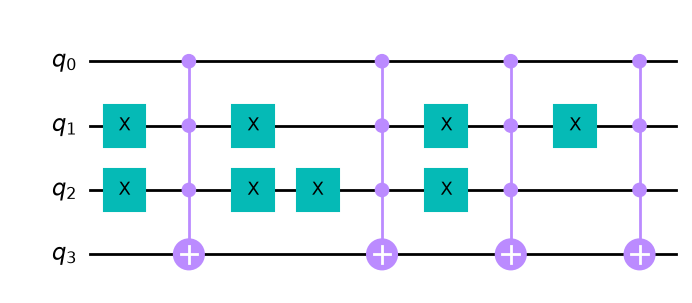

↑ the last random oracle, truth table f = [0, 1, 0, 1, 0, 1, 0, 1]: one multi-controlled X per input with f(x) = 1, framed by X gates on the zero bits of x
(2) balanced_1 : P(000) = 0.017  author's rule -> BALANCED ✓   majority rule -> BALANCED ✓
(2) balanced_2 : P(000) = 0.002  author's rule -> BALANCED ✓   majority rule -> BALANCED ✓


(2) constant_0 : P(000) = 0.858  author's rule -> BALANCED ✗   majority rule -> CONSTANT ✓
(2) constant_1 : P(000) = 0.842  author's rule -> BALANCED ✗   majority rule -> CONSTANT ✓
(3) P(right verdict) of a majority vote over s shots   [constant_1: q = 0.842 | balanced_1: q = 0.983]
    s =  1:  0.8460 (exact 0.8418)   |   0.9859 (exact 0.9834)
    s =  3:  0.9325 (exact 0.9328)   |   0.9993 (exact 0.9992)
    s =  5:  0.9684 (exact 0.9692)   |   0.9999 (exact 1.0000)
    s = 11:  0.9966 (exact 0.9965)   |   1.0000 (exact 1.0000)
    s = 21:  0.9999 (exact 0.9999)   |   1.0000 (exact 1.0000)
    s = 51:  1.0000 (exact 1.0000)   |   1.0000 (exact 1.0000)


In [24]:
# Reference solution
from math import comb                                   # binomial coefficient C(s, k)
rng = np.random.default_rng(2026)                       # reproducible random numbers

def oracle_from_table(n_qubits, table):
    """U_f for an arbitrary truth table: table[x] = f(x), with x read as an integer (bit q of x = input qubit q)."""
    oracle = QuantumCircuit(n_qubits + 1, name="Oracle_table")
    for x, fx in enumerate(table):
        if fx:                                          # flip the ancilla exactly when the input register holds x
            zeros = [q for q in range(n_qubits) if not (x >> q) & 1]   # x >> q & 1 = bit q of x
            if zeros: oracle.x(zeros)                   # map |x> to |11...1> ...
            oracle.mcx(list(range(n_qubits)), n_qubits) # multi-controlled X: ancilla flips iff all inputs are 1
            if zeros: oracle.x(zeros)                   # ... and back
    return oracle

def random_balanced_table(n_qubits, rng):
    N = 2 ** n_qubits
    table = np.zeros(N, dtype=int)
    table[rng.choice(N, N // 2, replace=False)] = 1     # 2^(n-1) distinct inputs get f = 1
    return table

def dj_from_oracle(n_qubits, oracle):
    """deutsch_jozsa_circuit with an arbitrary oracle circuit (same registers, so run_simulation still finds 'output')."""
    qr, anc = QuantumRegister(n_qubits, 'input'), QuantumRegister(1, 'ancilla')
    qc = QuantumCircuit(qr, anc, ClassicalRegister(n_qubits, 'output'))
    qc.x(anc); qc.h(qr); qc.h(anc)
    qc.compose(oracle, inplace=True)
    qc.h(qr); qc.measure(qr, qc.clbits)
    return qc

def predicted(table, n_qubits):
    """P(z) = |2^-n sum_x (-1)^(f(x) + x.z)|^2 for every z, as a dict {bitstring: probability}."""
    out = {}
    for z in range(2 ** n_qubits):
        a = sum((-1) ** (table[x] + bin(x & z).count("1")) for x in range(2 ** n_qubits)) / 2 ** n_qubits   # x.z = parity of x AND z
        if abs(a) > 1e-12: out[format(z, f"0{n_qubits}b")] = a ** 2                                        # format(z, '03b') -> '011'
    return out

# (1) the generator is unbiased, and DJ recognises every random balanced oracle
n3 = 3
draws = np.array([random_balanced_table(n3, rng) for _ in range(2000)])   # 2000 x 8 array of truth tables
freq = draws.mean(axis=0)                                                  # fraction of draws with f(x) = 1, input by input
print(f"(1) f(x) = 1 frequency per input over 2000 draws: {np.round(freq, 3)} (expected 0.5 ± {np.sqrt(0.25 / 2000):.3f})")
zeros_seen, tvds = 0, []
for k in range(20):
    table = random_balanced_table(n3, rng)
    counts = run_simulation(dj_from_oracle(n3, oracle_from_table(n3, table)), shots=1024)
    zeros_seen += counts.get('000', 0)                                     # dict.get(key, 0): 0 if '000' never appeared
    p = predicted(table, n3)
    tvds.append(0.5 * sum(abs(counts.get(z, 0) / 1024 - p.get(z, 0)) for z in set(counts) | set(p)))   # total variation distance
print(f"    20 random balanced oracles: {zeros_seen} shots on 000 in total; "
      f"distance measured vs predicted histogram: mean {np.mean(tvds):.3f}, max {np.max(tvds):.3f} (pure shot noise for 1024 shots is ~0.02-0.05)")
display(draw(oracle_from_table(n3, table))); print(f"↑ the last random oracle, truth table f = {table.tolist()}: one multi-controlled X per input with f(x) = 1, framed by X gates on the zero bits of x")

# (2) the four oracles of the notebook on the noisy stand-in of this edition
p0 = {}
for otype in oracle_types:
    counts = run_circuit(deutsch_jozsa_circuit(n3, otype), 2048)
    p0[otype] = counts.get('000', 0) / 2048
    author = "CONSTANT" if p0[otype] > 900 / 1024 else "BALANCED"         # the author's threshold, as a fraction
    majority = "CONSTANT" if p0[otype] > 0.5 else "BALANCED"
    expected = "CONSTANT" if 'constant' in otype else "BALANCED"
    print(f"(2) {otype:11s}: P(000) = {p0[otype]:.3f}  author's rule -> {author:8s} {'✓' if author == expected else '✗'}"
          f"   majority rule -> {majority:8s} {'✓' if majority == expected else '✗'}")

# (3) probability that a majority vote over s shots is right, for the hardest constant and the hardest balanced case
worst_c = min((o for o in oracle_types if 'constant' in o), key=lambda o: p0[o])        # constant: want 000, lowest P(000) is hardest
worst_b = max((o for o in oracle_types if 'balanced' in o), key=lambda o: p0[o])        # balanced: highest P(000) is hardest
print(f"(3) P(right verdict) of a majority vote over s shots   [{worst_c}: q = {p0[worst_c]:.3f} | {worst_b}: q = {1 - p0[worst_b]:.3f}]")
for s in (1, 3, 5, 11, 21, 51):
    row = []
    for o, q in ((worst_c, p0[worst_c]), (worst_b, 1 - p0[worst_b])):  # q = probability that ONE shot points to the right answer
        sim_ = np.mean(rng.binomial(s, q, size=20000) > s / 2)             # resampling: 20000 experiments of s shots each
        exact = sum(comb(s, k) * q**k * (1 - q)**(s - k) for k in range(s // 2 + 1, s + 1))   # binomial tail: more than s/2 right shots
        row.append(f"{sim_:.4f} (exact {exact:.4f})")
    print(f"    s = {s:2d}:  {row[0]}   |   {row[1]}")


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `oracle.mcx(controls, target)` | multi-controlled X: flips the ancilla only on \|11…1⟩; the X gates around it move that condition to the chosen input x |
| `rng.choice(N, N // 2, replace=False)` | 2^(n−1) *distinct* inputs: the table is balanced by construction; `draws.mean(axis=0)` checks that no input is favoured |
| `predicted(table, n)` | the Step 4 box formula evaluated for every z; `bin(x & z).count('1')` is the parity x·z |
| total variation distance | ½ Σ\|measured − predicted\|: 0 for identical histograms; with 1024 shots shot noise alone gives a few per cent |
| `run_circuit(circuit, 2048)` | the edition's noisy device (Step 5.4): the ideal 1-or-0 for P(000) becomes ≈ 0.8–0.95 vs ≈ 0.01–0.1 — the author's 900/1024 threshold can fail, the majority rule survives |
| `comb(s, k) * q**k * (1-q)**(s-k)` | the binomial law: the majority of s shots is right with a probability that tends to 1 exponentially fast in s |

</details>


## 📖 References

### Academic Papers

1. **Original Paper**:  
   Deutsch, D., & Jozsa, R. (1992). *Rapid solution of problems by quantum computation*.  
   Proceedings of the Royal Society of London A, 439(1907), 553-558.
   
2. **Improved Algorithm**:  
   Cleve, R., Ekert, A., Macchiavello, C., & Mosca, M. (1998).  
   *Quantum algorithms revisited*. Proceedings of the Royal Society A, 454(1969), 339-354.

### Online Resources

- [Qiskit Textbook - Deutsch-Jozsa](https://learn.qiskit.org/course/ch-algorithms/deutsch-jozsa-algorithm)
- [IBM Quantum Documentation](https://docs.quantum.ibm.com/)
- [Qiskit 2.2 Migration Guide](https://docs.quantum.ibm.com/migration-guides)

### Related Algorithms

- Deutsch Algorithm (special case: n=1)
- Bernstein-Vazirani Algorithm (extension)
- Simon's Algorithm (similar oracle-based approach)

---

**Author**: Quantum Computing Course  
**License**: MIT  
**Version**: 2.2.0 (Qiskit 2.2 Compatible)  
**Last Updated**: November 2025